In [ ]:
!pip install -q tensorflow
!pip install -q kaggle
!pip install -q seaborn
!pip install -q scikit-learn
!pip install -q pandas
!pip install -q matplotlib
!pip install -q pillow

In [16]:
import os
import zipfile
import shutil
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential
from tensorflow.keras.preprocessing import image

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_curve,
    auc,
    accuracy_score
)

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [ ]:
print("Available GPUs:")

gpus = tf.config.list_physical_devices('GPU')

if gpus:
    print("GPU available:")
    for gpu in gpus:
        print(gpu)
else:
    print("No GPU available. Training will use CPU.")

Available GPUs:
GPU available:
PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')


In [5]:
from google.colab import files

uploaded = files.upload()

Saving kaggle.json to kaggle.json


In [6]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

In [7]:
!ls -l ~/.kaggle/

total 4
-rw------- 1 root root 69 Oct 21 08:19 kaggle.json


In [8]:
!kaggle datasets download -d paultimothymooney/chest-xray-pneumonia

Dataset URL: https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia
License(s): other
100% 2.29G/2.29G [01:42<00:00, 24.1MB/s]



In [9]:
import zipfile
import os

zip_file = "chest-xray-pneumonia.zip"

with zipfile.ZipFile(zip_file, 'r') as zip_ref:
    zip_ref.extractall("chest_xray")

print("Dataset extracted successfully.")

Dataset extracted successfully.


In [11]:
for root, dirs, files in os.walk("chest_xray"):
    level = root.replace("chest_xray", "").count(os.sep)
    indent = " " * 4 * level
    print(indent + os.path.basename(root) + "/")

    if level < 3:
        for file in files[:5]:
            print(indent + "    " + file)

chest_xray/
    chest_xray/
        chest_xray/
            .DS_Store
            val/
                PNEUMONIA/
                NORMAL/
            test/
                PNEUMONIA/
                NORMAL/
            train/
                PNEUMONIA/
                NORMAL/
        val/
            PNEUMONIA/
            NORMAL/
        test/
            PNEUMONIA/
            NORMAL/
        train/
            PNEUMONIA/
            NORMAL/
        __MACOSX/
            ._chest_xray
            chest_xray/
                val/
                    PNEUMONIA/
                    NORMAL/
                test/
                    PNEUMONIA/
                    NORMAL/
                train/
                    PNEUMONIA/
                    NORMAL/


In [12]:
BASE_DIR = "chest_xray/chest_xray"

TRAIN_DIR = os.path.join(BASE_DIR, "train")
VAL_DIR = os.path.join(BASE_DIR, "val")
TEST_DIR = os.path.join(BASE_DIR, "test")

print("Training directory:", TRAIN_DIR)
print("Validation directory:", VAL_DIR)
print("Testing directory:", TEST_DIR)

Training directory: chest_xray/chest_xray/train
Validation directory: chest_xray/chest_xray/val
Testing directory: chest_xray/chest_xray/test


In [13]:
print("Training classes:")
print(os.listdir(TRAIN_DIR))

print("\nValidation classes:")
print(os.listdir(VAL_DIR))

print("\nTesting classes:")
print(os.listdir(TEST_DIR))

Training classes:
['PNEUMONIA', 'NORMAL']

Validation classes:
['PNEUMONIA', 'NORMAL']

Testing classes:
['PNEUMONIA', 'NORMAL']


In [14]:
def count_images(directory):
    normal_count = len(os.listdir(os.path.join(directory, "NORMAL")))
    pneumonia_count = len(os.listdir(os.path.join(directory, "PNEUMONIA")))

    return normal_count, pneumonia_count


train_normal, train_pneumonia = count_images(TRAIN_DIR)
val_normal, val_pneumonia = count_images(VAL_DIR)
test_normal, test_pneumonia = count_images(TEST_DIR)

print("TRAIN")
print("NORMAL:", train_normal)
print("PNEUMONIA:", train_pneumonia)

print("\nVALIDATION")
print("NORMAL:", val_normal)
print("PNEUMONIA:", val_pneumonia)

print("\nTEST")
print("NORMAL:", test_normal)
print("PNEUMONIA:", test_pneumonia)

TRAIN
NORMAL: 1341
PNEUMONIA: 3875

VALIDATION
NORMAL: 8
PNEUMONIA: 8

TEST
NORMAL: 234
PNEUMONIA: 390


In [17]:
data = {
    "Dataset": ["Train", "Train", "Validation", "Validation", "Test", "Test"],
    "Class": [
        "NORMAL", "PNEUMONIA",
        "NORMAL", "PNEUMONIA",
        "NORMAL", "PNEUMONIA"
    ],
    "Count": [
        train_normal,
        train_pneumonia,
        val_normal,
        val_pneumonia,
        test_normal,
        test_pneumonia
    ]
}

df = pd.DataFrame(data)

df

,Dataset,Class,Count
0,Train,NORMAL,1341
1,Train,PNEUMONIA,3875
2,Validation,NORMAL,8
3,Validation,PNEUMONIA,8
4,Test,NORMAL,234
5,Test,PNEUMONIA,390


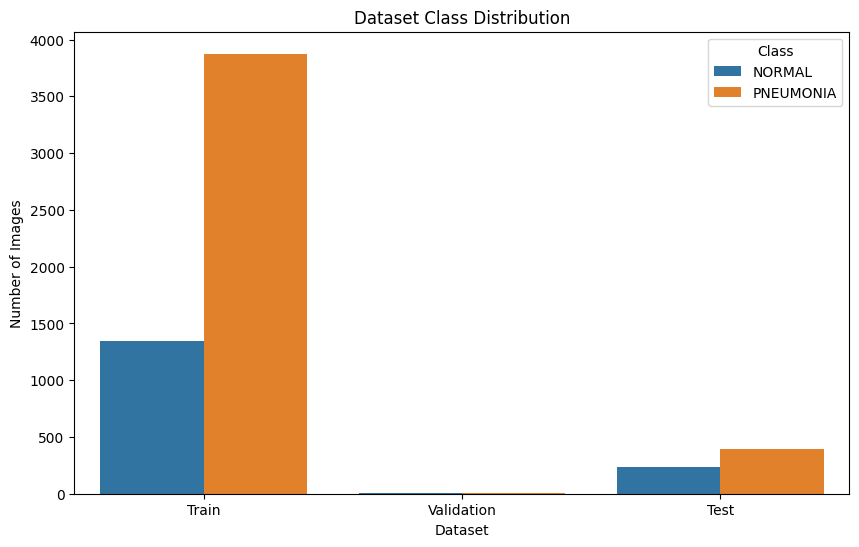

In [18]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=df,
    x="Dataset",
    y="Count",
    hue="Class"
)

plt.title("Dataset Class Distribution")
plt.ylabel("Number of Images")
plt.xlabel("Dataset")
plt.show()

In [19]:
normal_images = os.listdir(
    os.path.join(TRAIN_DIR, "NORMAL")
)

pneumonia_images = os.listdir(
    os.path.join(TRAIN_DIR, "PNEUMONIA")
)

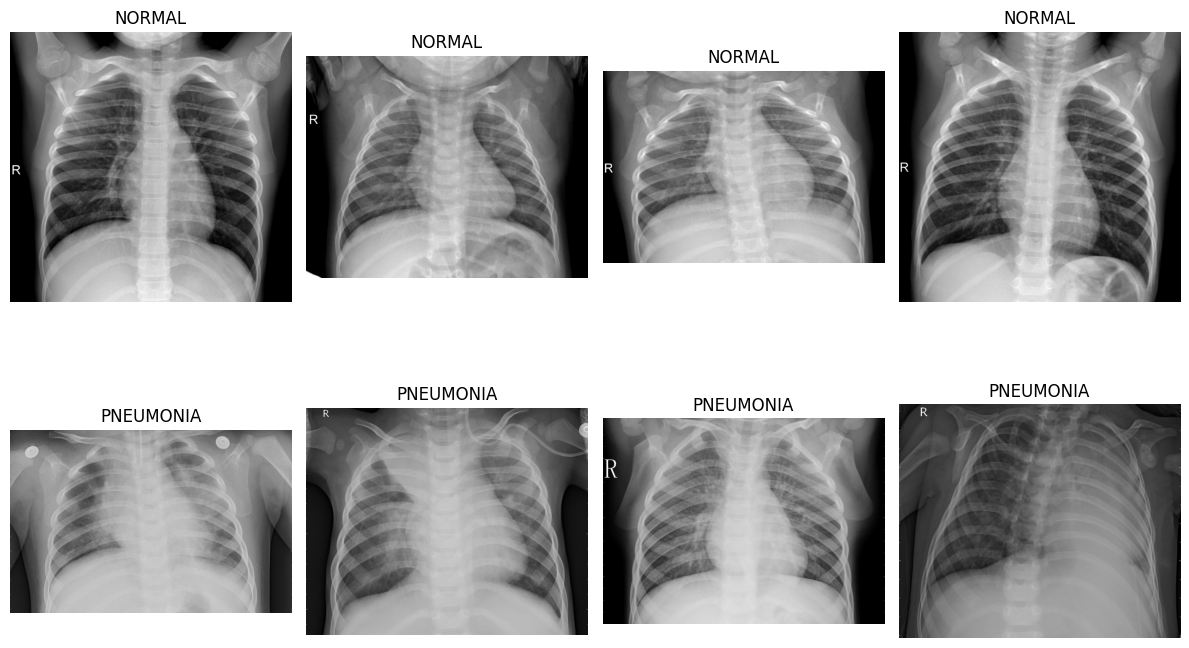

In [20]:
plt.figure(figsize=(12, 8))

for i in range(4):
    img_path = os.path.join(
        TRAIN_DIR,
        "NORMAL",
        normal_images[i]
    )

    img = Image.open(img_path)

    plt.subplot(2, 4, i + 1)
    plt.imshow(img, cmap="gray")
    plt.title("NORMAL")
    plt.axis("off")


for i in range(4):
    img_path = os.path.join(
        TRAIN_DIR,
        "PNEUMONIA",
        pneumonia_images[i]
    )

    img = Image.open(img_path)

    plt.subplot(2, 4, i + 5)
    plt.imshow(img, cmap="gray")
    plt.title("PNEUMONIA")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [21]:
sample_path = os.path.join(
    TRAIN_DIR,
    "NORMAL",
    normal_images[0]
)

img = Image.open(sample_path)

print("Image size:", img.size)
print("Image mode:", img.mode)

Image size: (2022, 1947)
Image mode: L


In [22]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

In [23]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    labels="inferred",
    label_mode="binary",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=SEED
)

Found 5216 files belonging to 2 classes.


In [24]:
val_ds = tf.keras.utils.image_dataset_from_directory(
    VAL_DIR,
    labels="inferred",
    label_mode="binary",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

Found 16 files belonging to 2 classes.


In [25]:
test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    labels="inferred",
    label_mode="binary",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

Found 624 files belonging to 2 classes.


In [26]:
class_names = train_ds.class_names

print(class_names)

['NORMAL', 'PNEUMONIA']


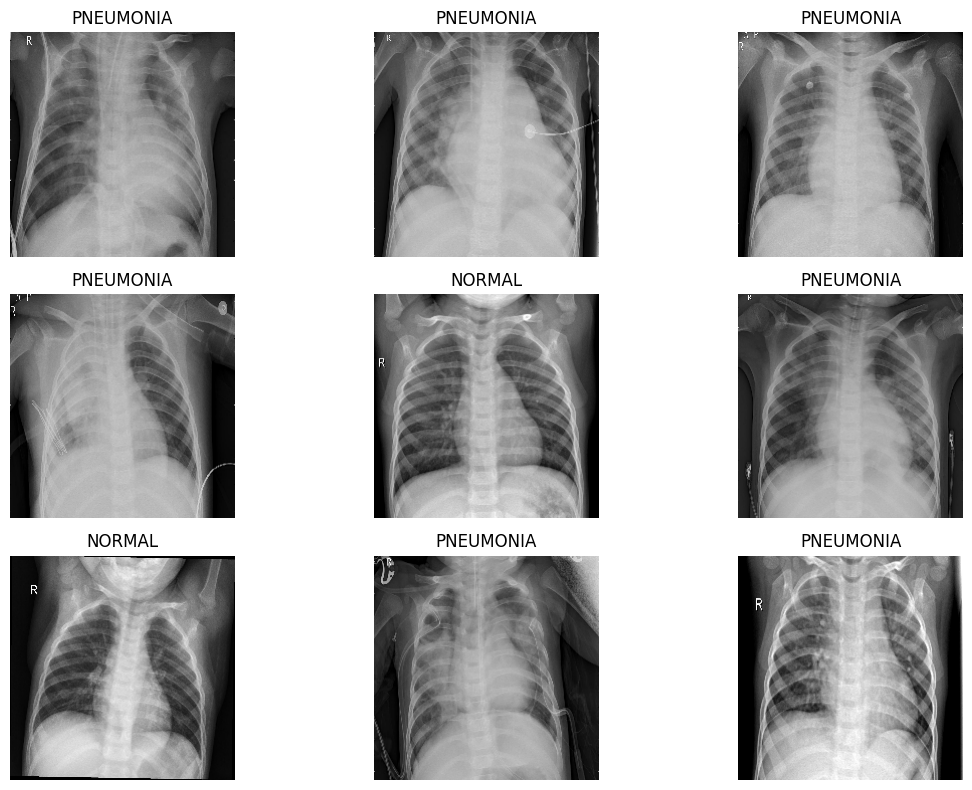

In [27]:
plt.figure(figsize=(12, 8))

for images, labels in train_ds.take(1):

    for i in range(9):
        plt.subplot(3, 3, i + 1)

        plt.imshow(
            images[i].numpy().astype("uint8")
        )

        label = int(labels[i].numpy()[0])

        plt.title(class_names[label])
        plt.axis("off")

plt.tight_layout()
plt.show()

In [28]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(
    buffer_size=AUTOTUNE
)

val_ds = val_ds.prefetch(
    buffer_size=AUTOTUNE
)

test_ds = test_ds.prefetch(
    buffer_size=AUTOTUNE
)

In [29]:
data_augmentation = Sequential([

    layers.RandomFlip(
        "horizontal"
    ),

    layers.RandomRotation(
        0.05
    ),

    layers.RandomZoom(
        0.10
    ),

    layers.RandomContrast(
        0.10
    )
])

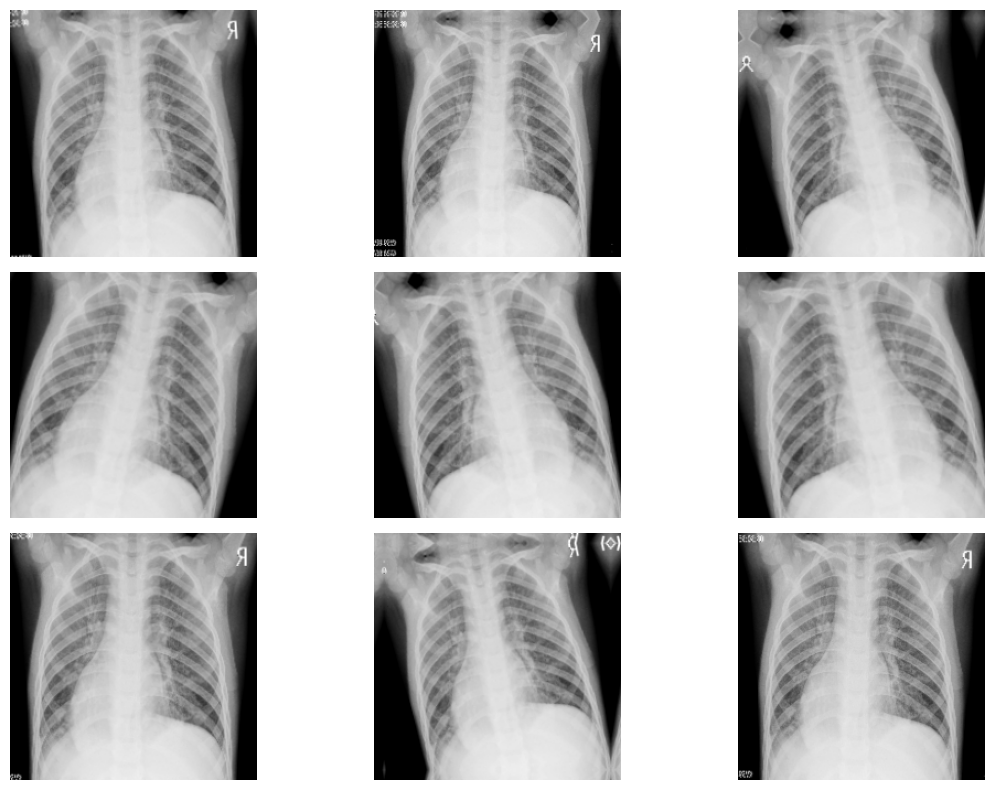

In [30]:
plt.figure(figsize=(12, 8))

for images, labels in train_ds.take(1):

    original_image = images[0]

    for i in range(9):

        augmented_image = data_augmentation(
            tf.expand_dims(original_image, 0),
            training=True
        )

        plt.subplot(3, 3, i + 1)

        plt.imshow(
            augmented_image[0].numpy().astype("uint8")
        )

        plt.axis("off")

plt.tight_layout()
plt.show()

In [31]:
#Custom CNN
#Build CNN Model
cnn_model = Sequential([

    layers.Input(
        shape=(224, 224, 3)
    ),

    # Data augmentation
    data_augmentation,

    # Normalize pixel values
    layers.Rescaling(
        1./255
    ),

    # Convolution Block 1
    layers.Conv2D(
        32,
        (3, 3),
        activation="relu"
    ),

    layers.MaxPooling2D(
        (2, 2)
    ),

    # Convolution Block 2
    layers.Conv2D(
        64,
        (3, 3),
        activation="relu"
    ),

    layers.MaxPooling2D(
        (2, 2)
    ),

    # Convolution Block 3
    layers.Conv2D(
        128,
        (3, 3),
        activation="relu"
    ),

    layers.MaxPooling2D(
        (2, 2)
    ),

    # Convolution Block 4
    layers.Conv2D(
        256,
        (3, 3),
        activation="relu"
    ),

    layers.MaxPooling2D(
        (2, 2)
    ),

    # Flatten
    layers.Flatten(),

    # Fully connected layer
    layers.Dense(
        128,
        activation="relu"
    ),

    # Dropout
    layers.Dropout(
        0.5
    ),

    # Binary output
    layers.Dense(
        1,
        activation="sigmoid"
    )
])

In [32]:
#Display CNN Architecture
cnn_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 24, 24, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 12, 12, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 36864)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,718,720 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,107,265 (19.48 MB)

 Trainable params: 5,107,265 (19.48 MB)

 Non-trainable params: 0 (0.00 B)

In [33]:
#Compile CNN
cnn_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),

    loss="binary_crossentropy",

    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

In [34]:
#CALLBACKS
callbacks = [

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    ),

    tf.keras.callbacks.ModelCheckpoint(
        "best_cnn_model.keras",
        monitor="val_loss",
        save_best_only=True
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-7
    )
]

In [35]:
#Train CNN
CNN_EPOCHS = 20

cnn_history = cnn_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=CNN_EPOCHS,
    callbacks=callbacks
)

Epoch 1/20
163/163 ━━━━━━━━━━━━━━━━━━━━ 35s 174ms/step - accuracy: 0.7868 - loss: 0.4674 - precision: 0.7897 - recall: 0.9719 - val_accuracy: 0.7500 - val_loss: 0.5616 - val_precision: 0.6667 - val_recall: 1.0000 - learning_rate: 1.0000e-04
Epoch 2/20
163/163 ━━━━━━━━━━━━━━━━━━━━ 38s 182ms/step - accuracy: 0.8997 - loss: 0.2445 - precision: 0.9280 - recall: 0.9378 - val_accuracy: 0.8125 - val_loss: 0.4833 - val_precision: 0.7273 - val_recall: 1.0000 - learning_rate: 1.0000e-04
Epoch 3/20
163/163 ━━━━━━━━━━━━━━━━━━━━ 29s 179ms/step - accuracy: 0.9243 - loss: 0.1990 - precision: 0.9505 - recall: 0.9474 - val_accuracy: 0.8125 - val_loss: 0.3872 - val_precision: 0.7778 - val_recall: 0.8750 - learning_rate: 1.0000e-04
Epoch 4/20
163/163 ━━━━━━━━━━━━━━━━━━━━ 41s 176ms/step - accuracy: 0.9358 - loss: 0.1747 - precision: 0.9569 - recall: 0.9566 - val_accuracy: 0.6250 - val_loss: 0.6377 - val_precision: 0.5714 - val_recall: 1.0000 - learning_rate: 1.0000e-04
Epoch 5/20
163/163 ━━━━━━━━━━━━━━━━━

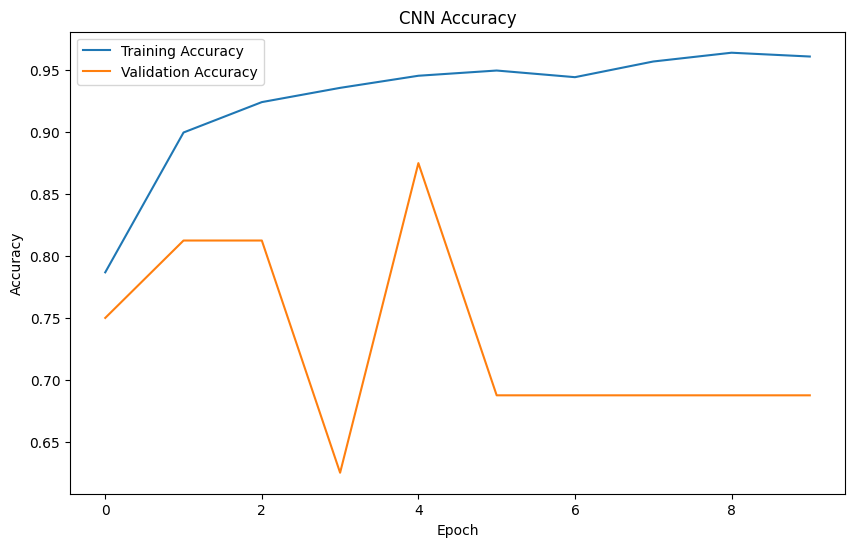

In [36]:
#plot CNN Accuracy
plt.figure(figsize=(10, 6))

plt.plot(
    cnn_history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    cnn_history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

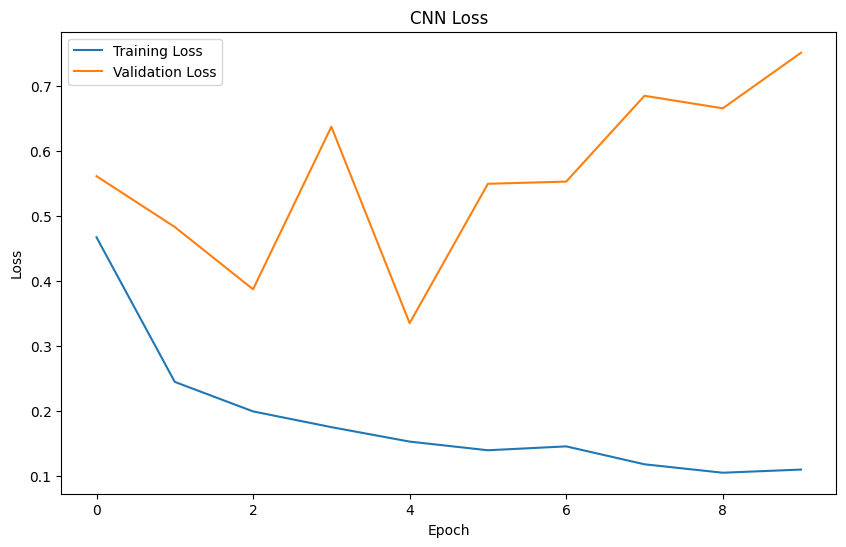

In [37]:
#Plot CNN Loss
plt.figure(figsize=(10, 6))

plt.plot(
    cnn_history.history["loss"],
    label="Training Loss"
)

plt.plot(
    cnn_history.history["val_loss"],
    label="Validation Loss"
)

plt.title("CNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [38]:
#Evaluate CNN
cnn_results = cnn_model.evaluate(
    test_ds,
    verbose=1
)

print("CNN Test Results:")
print(cnn_results)

20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 130ms/step - accuracy: 0.8622 - loss: 0.3415 - precision: 0.8439 - recall: 0.9564
CNN Test Results:
[0.34152185916900635, 0.8621794581413269, 0.8438913822174072, 0.9564102292060852]


In [39]:
#CNN Prediction
y_true = []
y_pred_probability = []

for images, labels in test_ds:

    predictions = cnn_model.predict(
        images,
        verbose=0
    )

    y_true.extend(
        labels.numpy().flatten()
    )

    y_pred_probability.extend(
        predictions.flatten()
    )

y_true = np.array(y_true)
y_pred_probability = np.array(
    y_pred_probability
)

y_pred = (
    y_pred_probability >= 0.5
).astype(int)

In [40]:
#CNN Classification Report
print(
    classification_report(
        y_true,
        y_pred,
        target_names=[
            "NORMAL",
            "PNEUMONIA"
        ]
    )
)

              precision    recall  f1-score   support

      NORMAL       0.91      0.71      0.79       234
   PNEUMONIA       0.84      0.96      0.90       390

    accuracy                           0.86       624
   macro avg       0.88      0.83      0.84       624
weighted avg       0.87      0.86      0.86       624



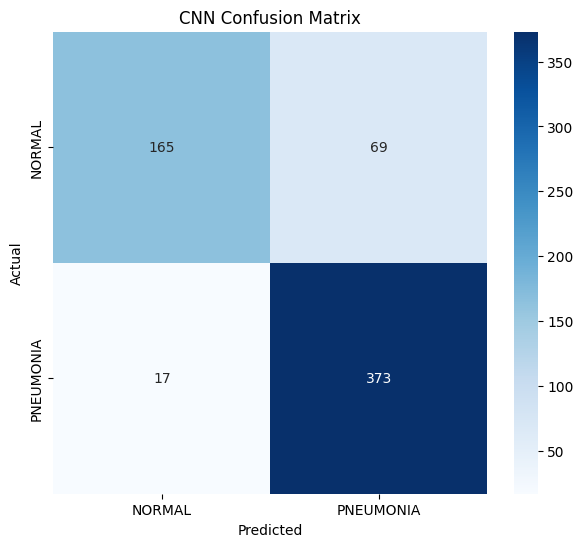

In [41]:
#CNN Confusion Matrix
cm = confusion_matrix(
    y_true,
    y_pred
)

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "NORMAL",
        "PNEUMONIA"
    ],
    yticklabels=[
        "NORMAL",
        "PNEUMONIA"
    ]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("CNN Confusion Matrix")

plt.show()

In [42]:
#TRANSFER LEARNING
from tensorflow.keras.applications import MobileNetV2

In [43]:
#load pretrained MobileNetV2
base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


In [44]:
#Freeze base model
base_model.trainable = False

In [45]:
#Build Transfer Learning model
inputs = keras.Input(
    shape=(224, 224, 3)
)

# Data augmentation
x = data_augmentation(inputs)

# MobileNetV2 preprocessing
x = tf.keras.applications.mobilenet_v2.preprocess_input(x)

# Pretrained base model
x = base_model(
    x,
    training=False
)

# Convert feature maps into vector
x = layers.GlobalAveragePooling2D()(x)

# Dropout
x = layers.Dropout(0.4)(x)

# Output
outputs = layers.Dense(
    1,
    activation="sigmoid"
)(x)

transfer_model = keras.Model(
    inputs,
    outputs
)

In [46]:
#Display Model
transfer_model.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [47]:
#compile Transfer learning model
transfer_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),

    loss="binary_crossentropy",

    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(
            name="precision"
        ),
        tf.keras.metrics.Recall(
            name="recall"
        )
    ]
)

In [48]:
#callbacks
transfer_callbacks = [

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    ),

    tf.keras.callbacks.ModelCheckpoint(
        "best_mobilenetv2_model.keras",
        monitor="val_loss",
        save_best_only=True
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-7
    )
]

In [49]:
#Train transer learning model
TRANSFER_EPOCHS = 15

transfer_history = transfer_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=TRANSFER_EPOCHS,
    callbacks=transfer_callbacks
)

Epoch 1/15
163/163 ━━━━━━━━━━━━━━━━━━━━ 37s 190ms/step - accuracy: 0.7049 - loss: 0.6124 - precision: 0.7460 - recall: 0.9141 - val_accuracy: 0.5000 - val_loss: 0.6816 - val_precision: 0.5000 - val_recall: 1.0000 - learning_rate: 1.0000e-04
Epoch 2/15
163/163 ━━━━━━━━━━━━━━━━━━━━ 30s 184ms/step - accuracy: 0.7692 - loss: 0.4671 - precision: 0.7865 - recall: 0.9461 - val_accuracy: 0.5625 - val_loss: 0.5693 - val_precision: 0.5333 - val_recall: 1.0000 - learning_rate: 1.0000e-04
Epoch 3/15
163/163 ━━━━━━━━━━━━━━━━━━━━ 41s 185ms/step - accuracy: 0.8175 - loss: 0.3941 - precision: 0.8279 - recall: 0.9523 - val_accuracy: 0.5625 - val_loss: 0.5284 - val_precision: 0.5333 - val_recall: 1.0000 - learning_rate: 1.0000e-04
Epoch 4/15
163/163 ━━━━━━━━━━━━━━━━━━━━ 40s 180ms/step - accuracy: 0.8508 - loss: 0.3376 - precision: 0.8617 - recall: 0.9520 - val_accuracy: 0.6250 - val_loss: 0.5037 - val_precision: 0.5714 - val_recall: 1.0000 - learning_rate: 1.0000e-04
Epoch 5/15
163/163 ━━━━━━━━━━━━━━━━━

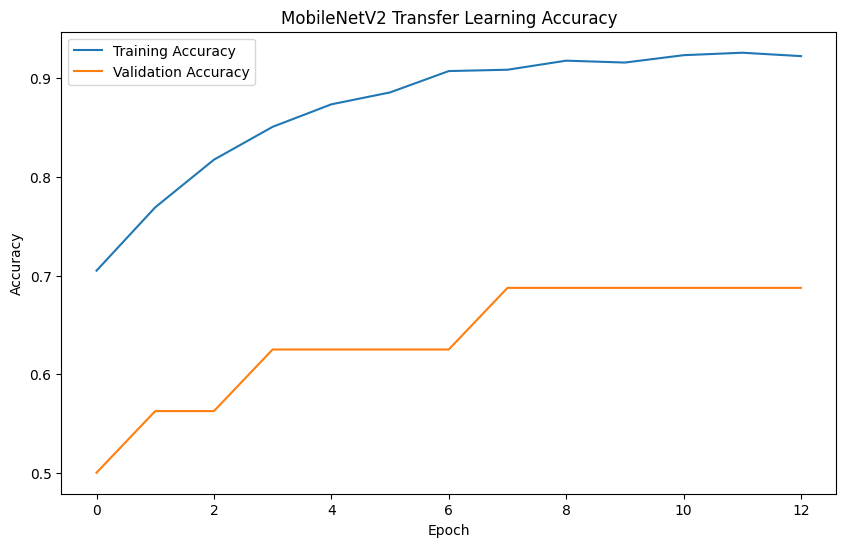

In [50]:
#plot transfer learning accuracy
plt.figure(figsize=(10, 6))

plt.plot(
    transfer_history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    transfer_history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title(
    "MobileNetV2 Transfer Learning Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.show()

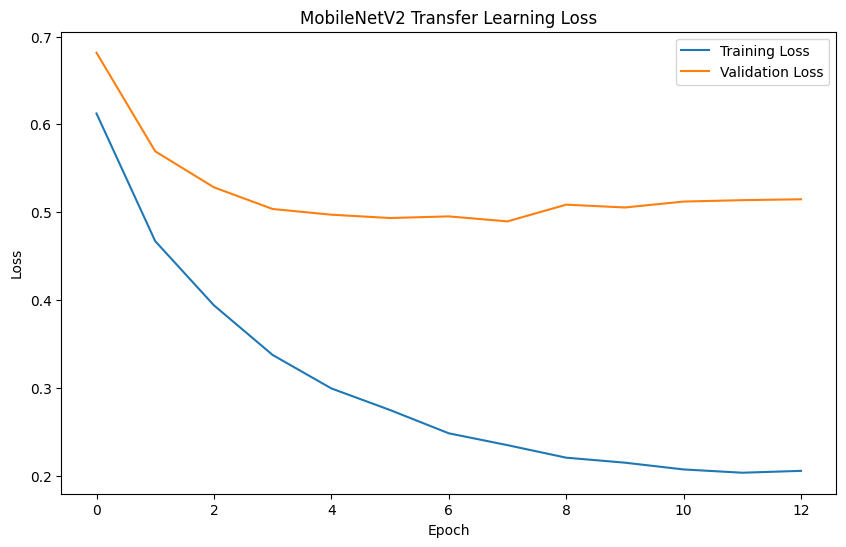

In [51]:
#Plot transfer learning loss
plt.figure(figsize=(10, 6))

plt.plot(
    transfer_history.history["loss"],
    label="Training Loss"
)

plt.plot(
    transfer_history.history["val_loss"],
    label="Validation Loss"
)

plt.title(
    "MobileNetV2 Transfer Learning Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.show()

In [52]:
#Transfer learning evaluation
transfer_results = transfer_model.evaluate(
    test_ds,
    verbose=1
)

print("Test Loss:", transfer_results[0])
print("Test Accuracy:", transfer_results[1])
print("Test Precision:", transfer_results[2])
print("Test Recall:", transfer_results[3])

20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 163ms/step - accuracy: 0.7388 - loss: 0.5057 - precision: 0.7060 - recall: 0.9974
Test Loss: 0.5056720972061157
Test Accuracy: 0.7387820482254028
Test Precision: 0.7059891223907471
Test Recall: 0.9974358677864075


In [53]:
#Transfer learning predictions
y_true = []
y_pred_probability = []

for images, labels in test_ds:

    predictions = transfer_model.predict(
        images,
        verbose=0
    )

    y_true.extend(
        labels.numpy().flatten()
    )

    y_pred_probability.extend(
        predictions.flatten()
    )

y_true = np.array(y_true)
y_pred_probability = np.array(
    y_pred_probability
)

# Convert probability to class
y_pred = (
    y_pred_probability >= 0.5
).astype(int)

In [54]:
#Transfer learning classification report
from sklearn.metrics import classification_report

print(
    classification_report(
        y_true,
        y_pred,
        target_names=[
            "NORMAL",
            "PNEUMONIA"
        ]
    )
)

              precision    recall  f1-score   support

      NORMAL       0.99      0.31      0.47       234
   PNEUMONIA       0.71      1.00      0.83       390

    accuracy                           0.74       624
   macro avg       0.85      0.65      0.65       624
weighted avg       0.81      0.74      0.69       624



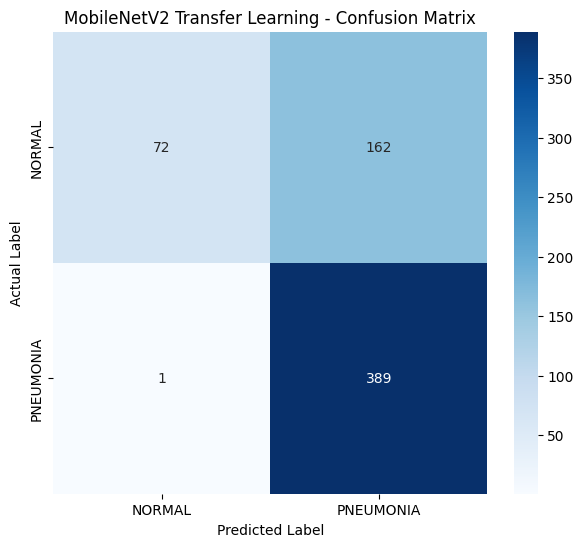

In [55]:
#Transfer learning confusion matrix
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Calculate confusion matrix
cm = confusion_matrix(y_true, y_pred)

# Plot confusion matrix
plt.figure(figsize=(7, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["NORMAL", "PNEUMONIA"],
    yticklabels=["NORMAL", "PNEUMONIA"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("MobileNetV2 Transfer Learning - Confusion Matrix")

plt.show()

In [56]:
#finetuning
# Unfreeze the MobileNetV2 base model
base_model.trainable = True

# Freeze the first 100 layers
fine_tune_at = 100

for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

In [57]:
#recompile model
transfer_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),

    loss="binary_crossentropy",

    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

In [58]:
#finetune the model
fine_tune_history = transfer_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=3,
            restore_best_weights=True
        ),

        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.2,
            patience=2,
            min_lr=1e-8
        )
    ]
)

Epoch 1/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 45s 195ms/step - accuracy: 0.8923 - loss: 0.2556 - precision: 0.9116 - recall: 0.9468 - val_accuracy: 0.5000 - val_loss: 1.4144 - val_precision: 0.5000 - val_recall: 1.0000 - learning_rate: 1.0000e-05
Epoch 2/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 31s 190ms/step - accuracy: 0.9402 - loss: 0.1594 - precision: 0.9636 - recall: 0.9556 - val_accuracy: 0.5000 - val_loss: 1.8074 - val_precision: 0.5000 - val_recall: 1.0000 - learning_rate: 1.0000e-05
Epoch 3/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 32s 193ms/step - accuracy: 0.9521 - loss: 0.1307 - precision: 0.9711 - recall: 0.9641 - val_accuracy: 0.5000 - val_loss: 1.8927 - val_precision: 0.5000 - val_recall: 1.0000 - learning_rate: 1.0000e-05
Epoch 4/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 41s 193ms/step - accuracy: 0.9590 - loss: 0.1132 - precision: 0.9709 - recall: 0.9739 - val_accuracy: 0.5000 - val_loss: 1.6409 - val_precision: 0.5000 - val_recall: 1.0000 - learning_rate: 2.0000e-06


In [59]:
#Evaluate finetuned model
results = transfer_model.evaluate(
    test_ds,
    verbose=1
)

print("Test Loss:", results[0])
print("Test Accuracy:", results[1])
print("Test Precision:", results[2])
print("Test Recall:", results[3])

20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 139ms/step - accuracy: 0.6522 - loss: 1.0800 - precision: 0.6425 - recall: 1.0000
Test Loss: 1.0800114870071411
Test Accuracy: 0.6522436141967773
Test Precision: 0.642504096031189
Test Recall: 1.0


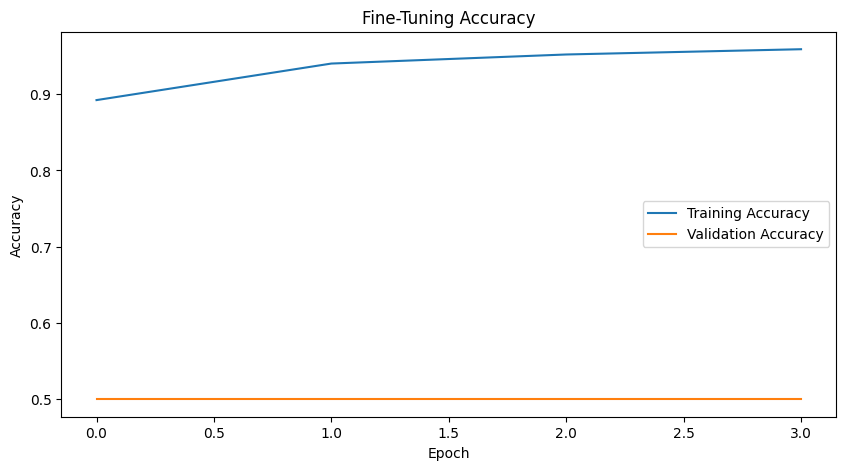

In [60]:
#Fine tuning accuracy and loss
plt.figure(figsize=(10, 5))

plt.plot(
    fine_tune_history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    fine_tune_history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Fine-Tuning Accuracy")
plt.legend()

plt.show()

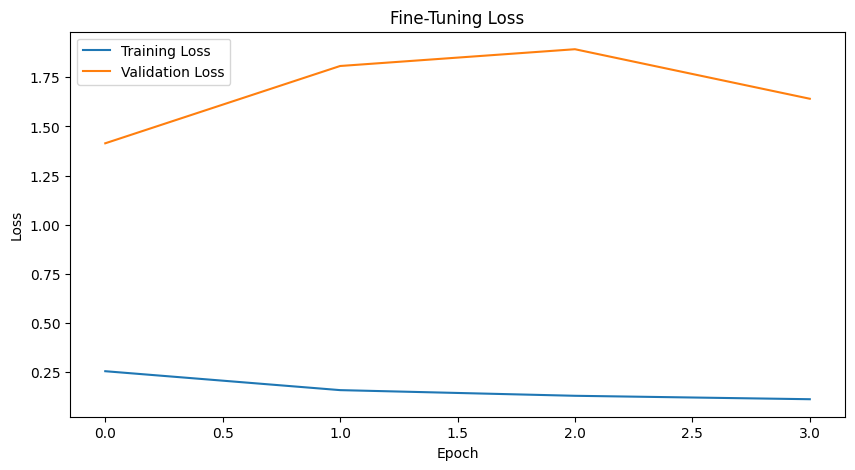

In [61]:
plt.figure(figsize=(10, 5))

plt.plot(
    fine_tune_history.history["loss"],
    label="Training Loss"
)

plt.plot(
    fine_tune_history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Fine-Tuning Loss")
plt.legend()

plt.show()

In [62]:
#classification report for finetuned model
from sklearn.metrics import classification_report

print("Classification Report - Fine-Tuned MobileNetV2")

print(classification_report(
    y_true,
    y_pred,
    target_names=["NORMAL", "PNEUMONIA"]
))

Classification Report - Fine-Tuned MobileNetV2
              precision    recall  f1-score   support

      NORMAL       0.99      0.31      0.47       234
   PNEUMONIA       0.71      1.00      0.83       390

    accuracy                           0.74       624
   macro avg       0.85      0.65      0.65       624
weighted avg       0.81      0.74      0.69       624



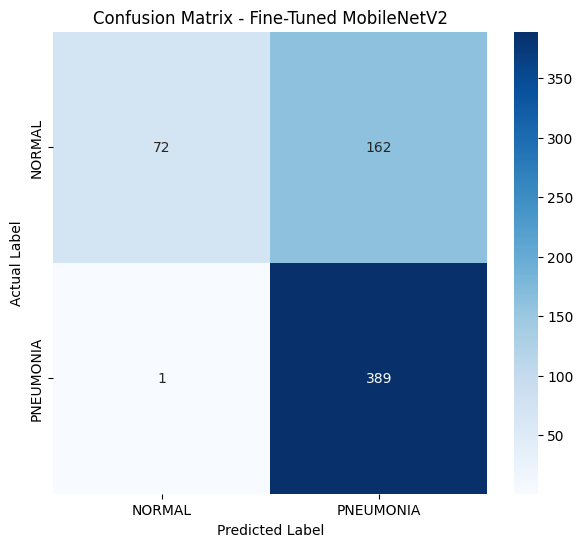

In [63]:
#Confusion matrix for finetuned model
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["NORMAL", "PNEUMONIA"],
    yticklabels=["NORMAL", "PNEUMONIA"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix - Fine-Tuned MobileNetV2")

plt.show()

In [64]:
#Prediction and saving model
def predict_pneumonia(image_path, model):

    img = tf.keras.utils.load_img(
        image_path,
        target_size=(224, 224)
    )

    img_array = tf.keras.utils.img_to_array(img)

    img_array = tf.expand_dims(
        img_array,
        axis=0
    )

    prediction = model.predict(
        img_array,
        verbose=0
    )[0][0]

    if prediction >= 0.5:
        predicted_class = "PNEUMONIA"
        confidence = prediction
    else:
        predicted_class = "NORMAL"
        confidence = 1 - prediction

    return predicted_class, confidence

In [88]:
#Test a new X-Ray
from google.colab import files

uploaded = files.upload()

Saving sample_true2.jpeg to sample_true2 (2).jpeg


In [90]:
import os

# Automatically detect the most recently uploaded file name
uploaded_files = list(uploaded.keys())
if uploaded_files:
    image_path = uploaded_files[-1]
    print(f"Processing most recent upload: {image_path}")

    # Using our custom cnn_model which has a more balanced performance
    predicted_class, confidence = predict_pneumonia(
        image_path,
        cnn_model
    )

    print("Prediction:", predicted_class)
    print(f"Confidence: {confidence * 100:.2f}%")
else:
    print("No files uploaded yet. Please upload an image first.")

Processing most recent upload: sample_true2 (2).jpeg
Prediction: NORMAL
Confidence: 93.00%


In [89]:
import tensorflow as tf

# Load the best weights of both models to make a robust ensemble prediction
try:
    best_mobilenet = tf.keras.models.load_model('best_mobilenetv2_model.keras')
    print("Loaded best MobileNetV2 model successfully.")
except Exception as e:
    best_mobilenet = transfer_model
    print("Using current transfer_model instead.")

def predict_ensemble(image_path):
    img = tf.keras.utils.load_img(image_path, target_size=(224, 224))
    img_array = tf.keras.utils.img_to_array(img)
    img_array = tf.expand_dims(img_array, axis=0)

    # Get predictions from both models
    pred_cnn = cnn_model.predict(img_array, verbose=0)[0][0]
    pred_mobilenet = best_mobilenet.predict(img_array, verbose=0)[0][0]

    # Average the predicted probabilities
    ensemble_pred = (pred_cnn + pred_mobilenet) / 2.0

    if ensemble_pred >= 0.5:
        predicted_class = "PNEUMONIA"
        confidence = ensemble_pred
    else:
        predicted_class = "NORMAL"
        confidence = 1.0 - ensemble_pred

    print(f"[CNN Pred: {pred_cnn:.4f} | MobileNet Pred: {pred_mobilenet:.4f}]")
    return predicted_class, confidence

if uploaded_files:
    image_path = uploaded_files[-1]
    predicted_class, confidence = predict_ensemble(image_path)
    print(f"Ensemble Prediction: {predicted_class}")
    print(f"Ensemble Confidence: {confidence * 100:.2f}%")

Loaded best MobileNetV2 model successfully.


[CNN Pred: 0.0700 | MobileNet Pred: 0.7501]
Ensemble Prediction: NORMAL
Ensemble Confidence: 59.00%


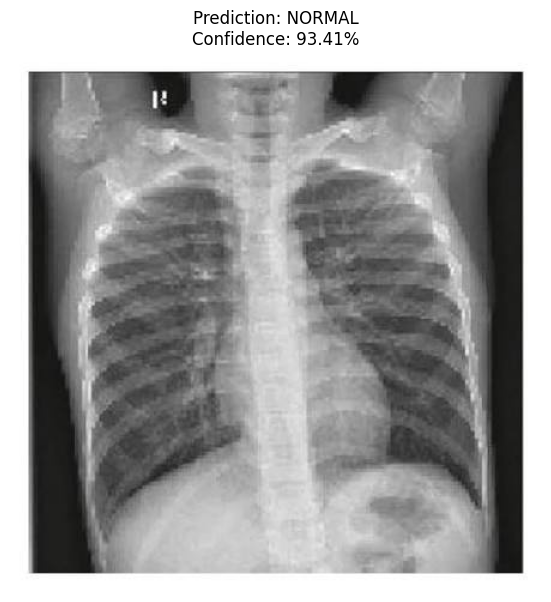

In [ ]:
#Display X-Ray with prediction
img = Image.open(image_path)

plt.figure(figsize=(7, 7))

plt.imshow(img, cmap="gray")

plt.title(
    f"Prediction: {predicted_class}\n"
    f"Confidence: {confidence * 100:.2f}%"
)

plt.axis("off")
plt.show()

File: sample_true2 (2).jpeg
Raw Pneumonia Probability: 0.0700 (Decision Threshold: 0.85)
Adjusted Prediction: NORMAL (93.00% confidence)


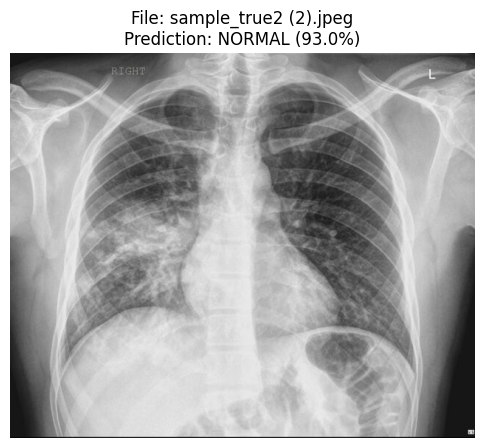

In [91]:
#@title Interactive Prediction with Adjustable Decision Threshold
#@markdown Adjust the threshold slider below. A higher threshold makes the model conservative, predicting PNEUMONIA only when it is highly confident.

threshold = 0.85 #@param {type:"slider", min:0.1, max:0.99, step:0.05}

def predict_with_threshold(image_path, model, thresh):
    img = tf.keras.utils.load_img(image_path, target_size=(224, 224))
    img_array = tf.keras.utils.img_to_array(img)
    img_array = tf.expand_dims(img_array, axis=0)

    # Get raw probability of pneumonia (value between 0 and 1)
    raw_prob = model.predict(img_array, verbose=0)[0][0]

    if raw_prob >= thresh:
        predicted_class = "PNEUMONIA"
        confidence = raw_prob
    else:
        predicted_class = "NORMAL"
        confidence = 1.0 - raw_prob

    return predicted_class, confidence, raw_prob

if uploaded_files:
    latest_image = uploaded_files[-1]

    # Using cnn_model for prediction
    pred_class, conf, raw_val = predict_with_threshold(latest_image, cnn_model, threshold)

    print(f"File: {latest_image}")
    print(f"Raw Pneumonia Probability: {raw_val:.4f} (Decision Threshold: {threshold})")
    print(f"Adjusted Prediction: {pred_class} ({conf*100:.2f}% confidence)")

    # Display image
    img = Image.open(latest_image)
    plt.figure(figsize=(6, 6))
    plt.imshow(img, cmap="gray")
    plt.title(f"File: {latest_image}\nPrediction: {pred_class} ({conf*100:.1f}%)")
    plt.axis("off")
    plt.show()
else:
    print("Please upload an X-ray image first using the upload cell.")

In [ ]:
#Save the final model
transfer_model.save(
    "pneumonia_mobilenetv2_final.keras"
)

print("Model saved successfully!")

Model saved successfully!


In [ ]:
#Load the saved model
loaded_model = tf.keras.models.load_model(
    "pneumonia_mobilenetv2_final.keras"
)

print("Model loaded successfully!")

Model loaded successfully!


In [ ]:
loaded_model.evaluate(test_ds)

20/20 ━━━━━━━━━━━━━━━━━━━━ 8s 218ms/step - accuracy: 0.8462 - loss: 0.4144 - precision: 0.8101 - recall: 0.9846


[0.4143795669078827,
 0.8461538553237915,
 0.8101266026496887,
 0.9846153855323792]